# HLLC Riemann solver

### Setup

In [1]:
import matplotlib.pyplot as pl
import numpy as np
import time

### HLLC

In [2]:
def hllc(lr,gamma=1.4,verbose=0,diag=None):
    qleft,qright=lr
    
    if gamma==1:
        g1=1.
    else:
        g1=1./(gamma-1.0)
    i,n=qleft.shape
    flux=np.zeros((3,n))
    
    if type(diag) is dict:
        diag['case']=[]
        diag['SL']=[]
        diag['SR']=[]
        diag['ro']=[]
        diag['uo']=[]
        diag['Po']=[]
        diag['eo']=[]

    for i in range(n):
        # Left variables
        rl=qleft[0,i]
        Pl=qleft[1,i]
        ul=qleft[2,i]
        el = Pl*g1+0.5*ul**2*rl

        # Right variables
        rr=qright[0,i]
        Pr=qright[1,i]
        ur=qright[2,i]
        er = Pr*g1+0.5*ur**2*rr

        # Find the largest eigenvalues in the normal direction to the interface
        cfastl = (gamma*Pl/rl)**0.5
        cfastr = (gamma*Pr/rr)**0.5

        # HLL wave speed
        SL=min(ul,ur)-max(cfastl,cfastr)
        SR=max(ul,ur)+max(cfastl,cfastr)

        # Sample the solution at x/t=0
        if SL > 0.0:       # supersonic positive speed
            icase=1
            ro=rl
            uo=ul
            Po=Pl
            eo=el
        elif SR < 0.0:     # supersonic negative speed
            icase=4
            ro=rr
            uo=ur
            Po=Pr
            eo=er
        else:
            # Lagrangian sound speed
            rcl=rl*(ul-SL)
            rcr=rr*(SR-ur)

            # Acoustic star state
            uo=(rcr*ur   +rcl*ul   +  (Pl-Pr))/(rcr+rcl)
            Po=(rcr*Pl+rcl*Pr+rcl*rcr*(ul-ur))/(rcr+rcl)

            # Left / right star region variables
            if uo > 0.0:        # positive momentum transport
                icase=2
                ro=rl*(SL-ul)/(SL-uo)
                eo=((SL-ul)*el-Pl*ul+Po*uo)/(SL-uo)
            else:               # negative momentum transport
                icase=3
                ro=rr*(SR-ur)/(SR-uo)
                eo=((SR-ur)*er-Pr*ur+Po*uo)/(SR-uo)

        if verbose:
            pbzrint(('{:4d}{:3d}'+8*'{:8.3f}').format(i,icase,SL,SR,SAL,SAR,ro,uo,Po,eo))

        if type(diag) is dict:
            diag['case'].append(icase)
            diag['SL'].append(SL)
            diag['SR'].append(SR)
            diag['ro'].append(ro)
            diag['uo'].append(uo)
            diag['Po'].append(Po)
            diag['eo'].append(eo)

        flux[0,i] = ro*uo
        flux[1,i] = (eo+Po)*uo
        flux[2,i] = ro*uo*uo+Po

    return flux

n=5000
left=np.ones((3,n))
rght=np.ones((3,n))

start=time.time()
flux=hllc((left,rght))
print('{:.1f} microsec/cell'.format(1e6*(time.time()-start)/n))

9.4 microsec/cell


### Slope limiter (MonCen)

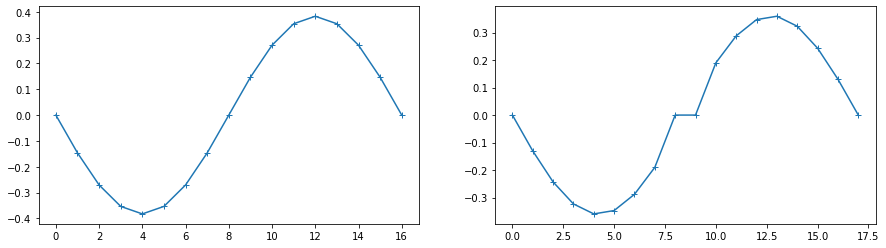

In [3]:
def moncen(q):
    n=len(q)
    df=np.zeros(n)

    for i in range(1,n-1):
        dl = q[i  ] - q[i-1]
        dr = q[i+1] - q[i  ]
        dc = 0.5*(dl+dr)
        sl = 2*min(abs(dl),abs(dr)) if dl*dr > 0 else 0.0
        df[i] = np.sign(dc)*min(sl,abs(dc))

    df[0]=0.0
    df[-1]=0.0
    return df

def slope(q,method='moncen'):
    if method=='moncen':
        return moncen(q)

def slopes(f,method='moncen'):
    df=np.zeros(f.shape)
    for i,v in enumerate(f):
        df[i]=slope(v,method=method)
    return df

pl.figure(figsize=(15,4))
pl.subplot(1,2,1); n=16; pl.plot(slope(np.cos(np.linspace(0,2*np.pi,n+1))),'-+');
pl.subplot(1,2,2); n=17; pl.plot(slope(np.cos(np.linspace(0,2*np.pi,n+1))),'-+');

## Initial conditions

### Stationary shock

The Rankine-Hugoniot relations are
$$
\frac{\rho_2}{\rho_1} = \frac{(\gamma+1){\scr M}^2}{(\gamma-1){\scr M}^2+2} 
$$

$$
\frac{P_2}{P_1} = 1+\frac{2\gamma}{\gamma+1} ({\scr M}^2-1)
$$

where, wirth $c_1$ the upstream sound speed:
$$
u_1 = {\scr M} c_1
$$

Since entropy $S$ per unit mass is
$$
S = \frac{\ln(P/\rho^\gamma)}{\gamma-1}
$$
the jump in $S$ is
$$
S_2 - S_1 = \frac{1}{\gamma-1}\left\{\ln(P_2/P_1)-\gamma\ln(\rho_2/\rho_1)\right\}
$$

#### Implementation

In [4]:
def stationary_shock(n=64,rl=1.0,cs=1.0,mach=2,gamma=1.4,m=None):
    r=(gamma+1)*mach**2/((gamma-1)*mach**2+2)
    p=1+(2*gamma)/(gamma+1)*(mach**2-1)
    rr=r*rl
    ul=mach*cs
    ur=ul/r
    pl=rl*cs**2/gamma
    pr=pl*p
    el=0.5*rl*ul**2+pl/(gamma-1)
    er=0.5*rr*ur**2+pr/(gamma-1)
    x=np.linspace(0,1,n)
    if m is None:
        m=n//2
    f=np.zeros((3,n))
    f[0,0:m]=rl
    f[0,m:n]=rr
    f[1,0:m]=el
    f[1,m:n]=er
    f[2,0:m]=rl*ul
    f[2,m:n]=rr*ur
    f[:,m-1]=0.9*f[:,m-2]+0.1*f[:,m+2]
    f[:,m  ]=0.5*f[:,m-2]+0.5*f[:,m+2]
    f[:,m+1]=0.1*f[:,m-2]+0.9*f[:,m+2]
    return x,f

### General shock initial conditions

In [5]:
def simple_shock(n=64,pl=2,pr=1,gamma=1.4,m=None):
    x=np.linspace(0,1,n)
    if m is None:
        m=n//2
    f=np.zeros((3,n))
    f[0]=1.0
    f[2]=0.0
    f[1,0:m]=pl/(gamma-1)
    f[1,m:n]=pr/(gamma-1)
    f[1,m-1]=0.9*f[1,m-2]+0.1*f[1,m+2]
    f[1,m  ]=0.5*f[1,m-2]+0.5*f[1,m+2]
    f[1,m+1]=0.1*f[1,m-2]+0.9*f[1,m+2]
    return x,f

### IC chooser

In [6]:
def IC(case='simple_shock',**kwarg):
    if case=='simple_shock':
        return simple_shock(**kwarg)
    if case=='stationary_shock':
        return stationary_shock(**kwarg)

### Simple test

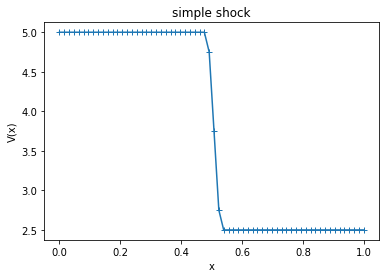

In [7]:
x,f=IC()
pl.plot(x,f[1],'-+');
pl.xlabel('x'); pl.ylabel('V(x)'); pl.title('simple shock');

### Primitive variables

In [8]:
def ctoprim(f,gamma=1.4):
    m,n=f.shape
    d=f[0]
    e=f[1]
    p=f[2]
    u=p/d
    p=(gamma-1)*(e-0.5*d*u**2)
    return np.array((d,p,u))

### Predictor

In [9]:
def predict(f):
    left=[]
    rght=[]
    for v in f:
        dv=slope(v)
        left.append(v+0.5*dv)
        rght.append(v-0.5*dv)
    left=np.roll(left,1,axis=1)
    left[:,0]=left[:,1]
    return np.array(left),np.array(rght)

Test

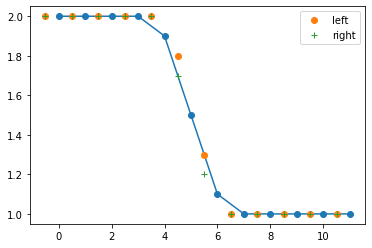

In [10]:
n=12
x,f=simple_shock(n=n,m=5)
x=np.arange(n)
p=ctoprim(f)
l,r=predict(p)
pl.plot(x,p[1],'-o')
pl.plot(x-0.5,l[1],'o',label='left')
pl.plot(x-0.5,r[1],'+',label='right')
pl.legend();

### Flux

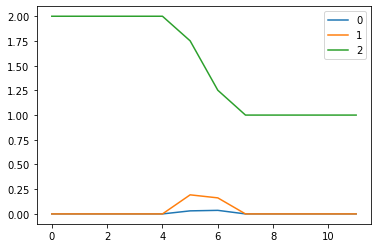

In [11]:
flux=hllc((l,r))
for i,v in enumerate(flux):
    pl.plot(v,label=i)
pl.legend();

### Boundary conditions

In [12]:
def BCs(df):
    df[:,0]=0.0
    df[:,-1]=0.0
    return df

### Flux divergence

In [13]:
def div(flux):
    df=np.roll(flux,-1,axis=1)-flux
    df[:,0]=0.0
    return df

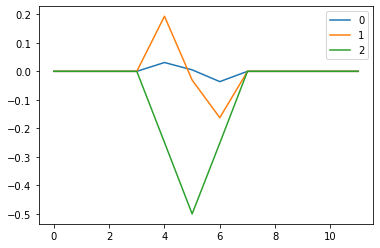

In [14]:
df=BCs(div(flux))
for i,v in enumerate(df):
    pl.plot(v,label=i)
pl.legend();

## Complete experiment

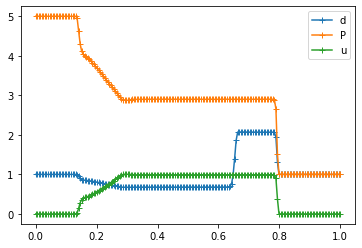

In [15]:
dtds=0.1
nstep=300
x,f=IC(n=200,pl=5)
for i in range(nstep):
    f -= dtds*BCs(div(hllc(predict(ctoprim(f)))))

labels=['d','P','u']
for i,v in enumerate(ctoprim(f)):
    pl.plot(x,v,'-+',label=labels[i])
pl.legend();

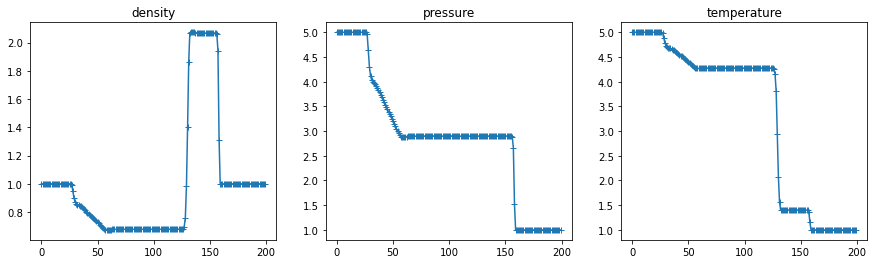

In [16]:
prim=ctoprim(f)
pl.figure(figsize=(15,4))
pl.subplot(1,3,1); pl.plot(prim[0],'-+'); pl.title('density')
pl.subplot(1,3,2); pl.plot(prim[1],'-+'); pl.title('pressure')
pl.subplot(1,3,3); pl.plot(prim[1]/prim[0],'-+'); pl.title('temperature');

### Local diagnostics

In [17]:
diag={}
pred=predict(ctoprim(f))
flux=hllc(pred,diag=diag)
diag.keys()

dict_keys(['case', 'SL', 'SR', 'ro', 'uo', 'Po', 'eo'])

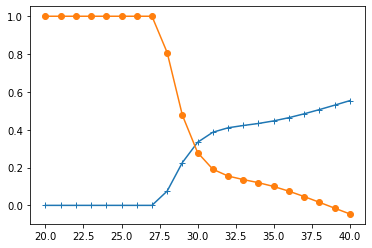

In [18]:
ii=20+np.arange(21)
pl.plot(ii,np.array(diag['uo'])[ii],'-+');
pl.plot(ii,flux[2,ii]-4,'-o');

### Stationary shock test

Show initial conditions

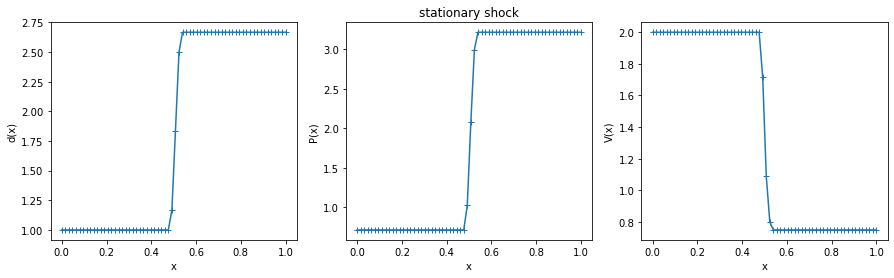

In [19]:
gamma=1.4
x,f=IC('stationary_shock',gamma=gamma)
pl.figure(figsize=(15,4))
pl.subplot(1,3,1); pl.plot(x,f[0],'-+');
pl.xlabel('x'); pl.ylabel('d(x)')
P=(gamma-1)*(f[1]-0.5*f[2]**2/f[0])
pl.subplot(1,3,2); pl.plot(x,P,'-+');
pl.xlabel('x'); pl.ylabel('P(x)'); pl.title('stationary shock');
pl.subplot(1,3,3); pl.plot(x,f[2]/f[0],'-+');
pl.xlabel('x'); pl.ylabel('V(x)');

Run the stationary shock:

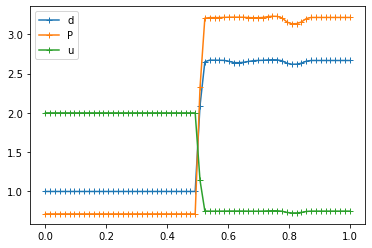

In [20]:
dtds=0.1
nstep=100
gamma=1.4
x,f=IC('stationary_shock',gamma=gamma)

for i in range(nstep):
    f -= dtds*BCs(div(hllc(predict(ctoprim(f)))))

labels=['d','P','u']
for i,v in enumerate(ctoprim(f)):
    pl.plot(x,v,'-+',label=labels[i])
pl.legend();

So, a small adjustment happens immediately after launch, and to get a good initial condition for tests that perturbuation should be allowed to propagate out

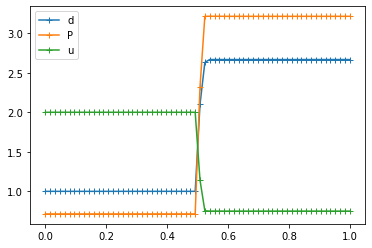

In [21]:
dtds=0.1
nstep=1000
gamma=1.4
x,f=IC('stationary_shock',gamma=gamma)

for i in range(nstep):
    f -= dtds*BCs(div(hllc(predict(ctoprim(f)))))

labels=['d','P','u']
for i,v in enumerate(ctoprim(f)):
    pl.plot(x,v,'-+',label=labels[i])
pl.legend();